# Laboratorium 2: Wstęp do pandas i wizualizacja danych

**Plan zajęć**
- **Część A – pandas** (ok. 50 min): tworzenie `DataFrame`, inspekcja, sortowanie, wybieranie kolumn, filtrowanie, nowe kolumny → zadania 1–6 i zadanie zaawansowane.
- **Część B – wizualizacja** (ok. 40 min): wykres słupkowy, punktowy i liniowy w trzech bibliotekach (matplotlib, pandas, seaborn), format szeroki i długi (`melt`) → zadania 7–10.

Notebook umieść w swoim repozytorium na GitHubie przed kolejnymi zajęciami.

In [54]:
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# from pandas.conftest import ascending

# Ustawienia dla polskich znaków i czytelności wykresów
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams.update({'font.size': 12})
sns.set_style("whitegrid")

# **Część A: Wstęp do pandas**

`Pandas` to biblioteka w Pythonie, która umożliwia łatwe i efektywne manipulowanie oraz analizowanie danych.

Jest szczególnie przydatna do pracy z danymi tabelarycznymi, podobnymi do tych w arkuszach kalkulacyjnych.

## CZĘŚĆ 1: Tworzenie DataFrame z polskimi danymi

In [55]:
# Przykład 1: Dane o polskich miastach
data_miasta = {
    'Miasto': ['Warszawa', 'Kraków', 'Łódź', 'Wrocław', 'Poznań', 'Gdańsk', 'Szczecin'],
    'Województwo': ['mazowieckie', 'małopolskie', 'łódzkie', 'dolnośląskie',
                    'wielkopolskie', 'pomorskie', 'zachodniopomorskie'],
    'Populacja': [1863056, 779966, 672185, 643782, 532048, 470907, 395513],
    'Powierzchnia_km2': [517, 327, 293, 293, 262, 262, 301],
    'Rok_nadania_praw': [1413, 1257, 1423, 1242, 1253, 1263, 1243]
}

miasta = pd.DataFrame(data_miasta)
print(miasta)

     Miasto         Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa         mazowieckie    1863056               517              1413
1    Kraków         małopolskie     779966               327              1257
2      Łódź             łódzkie     672185               293              1423
3   Wrocław        dolnośląskie     643782               293              1242
4    Poznań       wielkopolskie     532048               262              1253
5    Gdańsk           pomorskie     470907               262              1263
6  Szczecin  zachodniopomorskie     395513               301              1243


## CZĘŚĆ 2: PODSTAWOWE METODY INSPEKCJI DANYCH

In [56]:
print(">>> .head() - Pierwsze 5 wierszy (lub inna liczba)")
print(miasta.head(3))

>>> .head() - Pierwsze 5 wierszy (lub inna liczba)
     Miasto  Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa  mazowieckie    1863056               517              1413
1    Kraków  małopolskie     779966               327              1257
2      Łódź      łódzkie     672185               293              1423


In [57]:
print(">>> .info() - Informacje o strukturze danych")
miasta.info()

>>> .info() - Informacje o strukturze danych
<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Miasto            7 non-null      str  
 1   Województwo       7 non-null      str  
 2   Populacja         7 non-null      int64
 3   Powierzchnia_km2  7 non-null      int64
 4   Rok_nadania_praw  7 non-null      int64
dtypes: int64(3), str(2)
memory usage: 412.0 bytes


In [58]:
print(">>> .shape - Wymiary DataFrame (wiersze, kolumny)")
print(f"Nasz DataFrame ma: {miasta.shape[0]} wierszy i {miasta.shape[1]} kolumn")

>>> .shape - Wymiary DataFrame (wiersze, kolumny)
Nasz DataFrame ma: 7 wierszy i 5 kolumn


In [59]:
print(">>> .describe() - Statystyki opisowe dla kolumn numerycznych")
print(miasta.describe())

>>> .describe() - Statystyki opisowe dla kolumn numerycznych
          Populacja  Powierzchnia_km2  Rok_nadania_praw
count  7.000000e+00          7.000000          7.000000
mean   7.653510e+05        322.142857       1299.142857
std    5.010882e+05         88.856492         81.581102
min    3.955130e+05        262.000000       1242.000000
25%    5.014775e+05        277.500000       1248.000000
50%    6.437820e+05        293.000000       1257.000000
75%    7.260755e+05        314.000000       1338.000000
max    1.863056e+06        517.000000       1423.000000


In [60]:
print(">>> .columns - Nazwy kolumn")
print(miasta.columns.tolist())

>>> .columns - Nazwy kolumn
['Miasto', 'Województwo', 'Populacja', 'Powierzchnia_km2', 'Rok_nadania_praw']


In [61]:
print(">>> .index - Indeks wierszy")
print(miasta.index)
# miasta.index = miasta.index + 1
# print(miasta.index)
# print(miasta)
# print(miasta.describe())
# print(miasta.info())
# print(miasta.shape[0],miasta.shape[1])


>>> .index - Indeks wierszy
RangeIndex(start=0, stop=7, step=1)


## CZĘŚĆ 3: SORTOWANIE DANYCH

In [62]:
print("1. Sortowanie rosnąco po populacji:")
print(miasta.sort_values("Populacja").head())

1. Sortowanie rosnąco po populacji:
     Miasto         Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
6  Szczecin  zachodniopomorskie     395513               301              1243
5    Gdańsk           pomorskie     470907               262              1263
4    Poznań       wielkopolskie     532048               262              1253
3   Wrocław        dolnośląskie     643782               293              1242
2      Łódź             łódzkie     672185               293              1423


In [63]:
print("2. Sortowanie malejąco po populacji:")
print(miasta.sort_values("Populacja", ascending=False).head())

2. Sortowanie malejąco po populacji:
     Miasto    Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa    mazowieckie    1863056               517              1413
1    Kraków    małopolskie     779966               327              1257
2      Łódź        łódzkie     672185               293              1423
3   Wrocław   dolnośląskie     643782               293              1242
4    Poznań  wielkopolskie     532048               262              1253


## CZĘŚĆ 4: WYBIERANIE KOLUMN

In [64]:
print("1. Jedna kolumna (zwraca Series):")
print(miasta["Miasto"])
print(f"\nTyp: {type(miasta['Miasto'])}")

1. Jedna kolumna (zwraca Series):
0    Warszawa
1      Kraków
2        Łódź
3     Wrocław
4      Poznań
5      Gdańsk
6    Szczecin
Name: Miasto, dtype: str

Typ: <class 'pandas.Series'>


In [65]:
print("2. Wiele kolumn (zwraca DataFrame):")
print(miasta[["Miasto", "Populacja"]])
print(f"\nTyp: {type(miasta[["Miasto", "Populacja"]])}")

2. Wiele kolumn (zwraca DataFrame):
     Miasto  Populacja
0  Warszawa    1863056
1    Kraków     779966
2      Łódź     672185
3   Wrocław     643782
4    Poznań     532048
5    Gdańsk     470907
6  Szczecin     395513

Typ: <class 'pandas.DataFrame'>


In [66]:
print("3. Używanie zmiennej z listą kolumn:")
kolumny_do_wyswietlenia = ["Miasto",
                           "Województwo",
                           "Populacja"]
print(miasta[kolumny_do_wyswietlenia])
print(f"\nTyp: {type(miasta[kolumny_do_wyswietlenia])}")

3. Używanie zmiennej z listą kolumn:
     Miasto         Województwo  Populacja
0  Warszawa         mazowieckie    1863056
1    Kraków         małopolskie     779966
2      Łódź             łódzkie     672185
3   Wrocław        dolnośląskie     643782
4    Poznań       wielkopolskie     532048
5    Gdańsk           pomorskie     470907
6  Szczecin  zachodniopomorskie     395513

Typ: <class 'pandas.DataFrame'>


## CZĘŚĆ 5: FILTROWANIE WIERSZY

In [67]:
print("1. Miasta z populacją powyżej 600 000:")
print(miasta[miasta["Populacja"] > 600000])

1. Miasta z populacją powyżej 600 000:
     Miasto   Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa   mazowieckie    1863056               517              1413
1    Kraków   małopolskie     779966               327              1257
2      Łódź       łódzkie     672185               293              1423
3   Wrocław  dolnośląskie     643782               293              1242


In [68]:
print("2. Miasta z województwa mazowieckiego:")
print(miasta[miasta["Województwo"] == "mazowieckie"])

2. Miasta z województwa mazowieckiego:
     Miasto  Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa  mazowieckie    1863056               517              1413


In [69]:
print("3. Miasta z prawami miejskimi przed 1300 rokiem:")
print(miasta[miasta["Rok_nadania_praw"] < 1300])

3. Miasta z prawami miejskimi przed 1300 rokiem:
     Miasto         Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
1    Kraków         małopolskie     779966               327              1257
3   Wrocław        dolnośląskie     643782               293              1242
4    Poznań       wielkopolskie     532048               262              1253
5    Gdańsk           pomorskie     470907               262              1263
6  Szczecin  zachodniopomorskie     395513               301              1243


In [70]:
print("4. Złożone warunki z operatorem AND (&):")
print("   Miasta powyżej 500k ludności I powierzchnia powyżej 280 km²")
duze_miasta = miasta[(miasta["Populacja"] > 500000) &
                     (miasta["Powierzchnia_km2"] > 280)]
print(duze_miasta)

4. Złożone warunki z operatorem AND (&):
   Miasta powyżej 500k ludności I powierzchnia powyżej 280 km²
     Miasto   Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa   mazowieckie    1863056               517              1413
1    Kraków   małopolskie     779966               327              1257
2      Łódź       łódzkie     672185               293              1423
3   Wrocław  dolnośląskie     643782               293              1242


In [71]:
print("5. Złożone warunki z operatorem OR (|):")
print("   Miasta z Warszawy LUB Krakowa")
stolice = miasta[(miasta["Miasto"] == "Warszawa") |
                 (miasta["Miasto"] == "Kraków")]
print(stolice)

5. Złożone warunki z operatorem OR (|):
   Miasta z Warszawy LUB Krakowa
     Miasto  Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa  mazowieckie    1863056               517              1413
1    Kraków  małopolskie     779966               327              1257


In [72]:
print("6. Używanie .isin() dla wielu wartości:")
wybrane_miasta = ["Warszawa", "Kraków", "Wrocław"]
print(miasta[miasta["Miasto"].isin(wybrane_miasta)])

6. Używanie .isin() dla wielu wartości:
     Miasto   Województwo  Populacja  Powierzchnia_km2  Rok_nadania_praw
0  Warszawa   mazowieckie    1863056               517              1413
1    Kraków   małopolskie     779966               327              1257
3   Wrocław  dolnośląskie     643782               293              1242


## CZĘŚĆ 6: DODAWANIE NOWYCH KOLUMN

In [73]:
print("1. Obliczanie gęstości zaludnienia:")
miasta["Gęstość_na_km2"] = miasta["Populacja"] / miasta["Powierzchnia_km2"]
print(miasta[["Miasto", "Populacja", "Powierzchnia_km2", "Gęstość_na_km2"]])

1. Obliczanie gęstości zaludnienia:
     Miasto  Populacja  Powierzchnia_km2  Gęstość_na_km2
0  Warszawa    1863056               517     3603.589942
1    Kraków     779966               327     2385.217125
2      Łódź     672185               293     2294.146758
3   Wrocław     643782               293     2197.208191
4    Poznań     532048               262     2030.717557
5    Gdańsk     470907               262     1797.354962
6  Szczecin     395513               301     1313.996678


In [74]:
print("2. Kategoryzacja miast według wielkości:")
def kategoryzuj_miasto(populacja):
    if populacja > 1000000:
        return "Bardzo duże"
    elif populacja > 500000:
        return "Duże"
    else:
        return "Średnie"

miasta["Kategoria"] = miasta["Populacja"].apply(kategoryzuj_miasto)
print(miasta[["Miasto", "Populacja", "Kategoria"]])

2. Kategoryzacja miast według wielkości:
     Miasto  Populacja    Kategoria
0  Warszawa    1863056  Bardzo duże
1    Kraków     779966         Duże
2      Łódź     672185         Duże
3   Wrocław     643782         Duże
4    Poznań     532048         Duże
5    Gdańsk     470907      Średnie
6  Szczecin     395513      Średnie


# **Zadania – część A**

In [75]:
# Dataset do zadań
temperatura = pd.DataFrame({
    'Miasto': ['Warszawa', 'Kraków', 'Gdańsk', 'Wrocław', 'Poznań', 'Łódź'],
    'Styczeń': [-2, -1, 0, -1, -2, -3],
    'Kwiecień': [9, 10, 8, 11, 10, 9],
    'Lipiec': [19, 20, 17, 21, 19, 20],
    'Październik': [9, 9, 10, 10, 9, 8]
})

print("Dataset 'temperatura' - średnie temperatury w polskich miastach:")
print(temperatura)

Dataset 'temperatura' - średnie temperatury w polskich miastach:
     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
2    Gdańsk        0         8      17           10
3   Wrocław       -1        11      21           10
4    Poznań       -2        10      19            9
5      Łódź       -3         9      20            8


## **Zadanie 1: podstawowa inspekcja**

Używając DataFrame `temperatura`, wykonaj następujące operacje:

a) Wyświetl pierwsze 3 wiersze

b) Wyświetl informacje o typach danych (.info())

c) Wyświetl kształt DataFrame (.shape)

d) Wyświetl tylko nazwy kolumn (.columns)

In [76]:
# A
print(f"First 3 rows:\n{temperatura.head(3)}")
# B
print(f"Data types info:")
temperatura.info()
# C
print(f"Rows: {temperatura.shape[0]}, Columns: {temperatura.shape[1]}")
# D
print(f"Column names:\n{temperatura.columns}")

First 3 rows:
     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
2    Gdańsk        0         8      17           10
Data types info:
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Miasto       6 non-null      str  
 1   Styczeń      6 non-null      int64
 2   Kwiecień     6 non-null      int64
 3   Lipiec       6 non-null      int64
 4   Październik  6 non-null      int64
dtypes: int64(4), str(1)
memory usage: 372.0 bytes
Rows: 6, Columns: 5
Column names:
Index(['Miasto', 'Styczeń', 'Kwiecień', 'Lipiec', 'Październik'], dtype='str')


## **Zadanie 2: sortowanie**

a) Posortuj miasta według temperatury w lipcu (rosnąco)

b) Posortuj miasta według temperatury w styczniu (malejąco)

c) Posortuj miasta według temperatury w lipcu malejąco,

d) Posortuj miasta według temperatury w kwietnia rosnąco

In [77]:
print(temperatura.sort_values(by='Lipiec'),"\n")
print(temperatura.sort_values(by='Styczeń', ascending=False),"\n")
print(temperatura.sort_values(by='Lipiec', ascending=False),"\n")
print(temperatura.sort_values(by="Kwiecień"))

     Miasto  Styczeń  Kwiecień  Lipiec  Październik
2    Gdańsk        0         8      17           10
0  Warszawa       -2         9      19            9
4    Poznań       -2        10      19            9
1    Kraków       -1        10      20            9
5      Łódź       -3         9      20            8
3   Wrocław       -1        11      21           10 

     Miasto  Styczeń  Kwiecień  Lipiec  Październik
2    Gdańsk        0         8      17           10
1    Kraków       -1        10      20            9
3   Wrocław       -1        11      21           10
0  Warszawa       -2         9      19            9
4    Poznań       -2        10      19            9
5      Łódź       -3         9      20            8 

     Miasto  Styczeń  Kwiecień  Lipiec  Październik
3   Wrocław       -1        11      21           10
1    Kraków       -1        10      20            9
5      Łódź       -3         9      20            8
0  Warszawa       -2         9      19            9
4    Poz

## **Zadanie 3: Wybieranie kolumn**

a) Wybierz tylko kolumnę 'Miasto' (wynik: Series)

b) Wybierz kolumny 'Miasto' i 'Lipiec' (wynik: DataFrame)

c) Wybierz kolumny 'Miasto', 'Styczeń' i 'Lipiec', używając zmiennej z listą nazw kolumn

In [78]:
print(temperatura["Miasto"],"\n")
print(temperatura[["Miasto", "Lipiec"]],"\n")
column_list = ["Miasto", "Styczeń", "Lipiec"]
print(temperatura[column_list])

0    Warszawa
1      Kraków
2      Gdańsk
3     Wrocław
4      Poznań
5        Łódź
Name: Miasto, dtype: str 

     Miasto  Lipiec
0  Warszawa      19
1    Kraków      20
2    Gdańsk      17
3   Wrocław      21
4    Poznań      19
5      Łódź      20 

     Miasto  Styczeń  Lipiec
0  Warszawa       -2      19
1    Kraków       -1      20
2    Gdańsk        0      17
3   Wrocław       -1      21
4    Poznań       -2      19
5      Łódź       -3      20


## **Zadanie 4: Filtrowanie**
a) Znajdź miasta, gdzie temperatura w lipcu jest większa niż 19 stopni

b) Znajdź miasta, gdzie temperatura w styczniu jest większa lub równa -1

c) Znajdź miasta, gdzie temperatura w kwietniu wynosi dokładnie 10 stopni

d) Znajdź miasta, gdzie temperatura w lipcu jest 20 LUB temperatura w styczniu jest -1

In [79]:
print(temperatura[temperatura["Lipiec"]>19],"\n")
print(temperatura[temperatura["Styczeń"]>=-1],"\n")
print(temperatura[temperatura["Kwiecień"]==10], "\n")
print(temperatura[(temperatura["Lipiec"]==20) | (temperatura["Styczeń"] == -1)])


    Miasto  Styczeń  Kwiecień  Lipiec  Październik
1   Kraków       -1        10      20            9
3  Wrocław       -1        11      21           10
5     Łódź       -3         9      20            8 

    Miasto  Styczeń  Kwiecień  Lipiec  Październik
1   Kraków       -1        10      20            9
2   Gdańsk        0         8      17           10
3  Wrocław       -1        11      21           10 

   Miasto  Styczeń  Kwiecień  Lipiec  Październik
1  Kraków       -1        10      20            9
4  Poznań       -2        10      19            9 

    Miasto  Styczeń  Kwiecień  Lipiec  Październik
1   Kraków       -1        10      20            9
3  Wrocław       -1        11      21           10
5     Łódź       -3         9      20            8


## **Zadanie 5: Złożone filtrowanie**
a) Znajdź miasta, gdzie temperatura w lipcu > 18 ORAZ w styczniu >= -2

b) Znajdź miasta: 'Warszawa', 'Kraków', 'Gdańsk'

c) Znajdź miasta, gdzie temperatura w lipcu jest między 18 a 20 stopni (włącznie)

In [80]:
print(temperatura[(temperatura["Lipiec"] > 18) & (temperatura["Styczeń"] >= -2)], "\n")
print(temperatura[(temperatura["Miasto"].isin(["Warszawa", "Kraków", "Gdańsk"]))], "\n")
print(temperatura[(temperatura["Lipiec"] >= 18) & (temperatura["Lipiec"] <= 20)])

     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
3   Wrocław       -1        11      21           10
4    Poznań       -2        10      19            9 

     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
2    Gdańsk        0         8      17           10 

     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
4    Poznań       -2        10      19            9
5      Łódź       -3         9      20            8


## **Zadanie 6: Dodawanie nowych kolumn**
a) Dodaj kolumnę 'Średnia_roczna' - średnia z wszystkich miesięcy

b) Dodaj kolumnę 'Amplituda' - różnica między lipcem a styczniem

c) Dodaj kolumnę 'Ciepłe_miasto' (True jeśli średnia roczna > 11, False w przeciwnym razie)

In [81]:
print(temperatura)
months = ["Styczeń", "Kwiecień", "Lipiec", "Październik"]
temperatura["Srednia_roczna"] = temperatura[months].mean(axis=1)
print("\n",temperatura)
temperatura["Amplituda"] = temperatura["Lipiec"] - temperatura["Styczeń"]
print("\n",temperatura)
temperatura["Ciepłe_miasto"] = temperatura["Srednia_roczna"] > 11
print("\n",temperatura)


     Miasto  Styczeń  Kwiecień  Lipiec  Październik
0  Warszawa       -2         9      19            9
1    Kraków       -1        10      20            9
2    Gdańsk        0         8      17           10
3   Wrocław       -1        11      21           10
4    Poznań       -2        10      19            9
5      Łódź       -3         9      20            8

      Miasto  Styczeń  Kwiecień  Lipiec  Październik  Srednia_roczna
0  Warszawa       -2         9      19            9            8.75
1    Kraków       -1        10      20            9            9.50
2    Gdańsk        0         8      17           10            8.75
3   Wrocław       -1        11      21           10           10.25
4    Poznań       -2        10      19            9            9.00
5      Łódź       -3         9      20            8            8.50

      Miasto  Styczeń  Kwiecień  Lipiec  Październik  Srednia_roczna  Amplituda
0  Warszawa       -2         9      19            9            8.75         2

## **Zadanie zaawansowane**

Uruchom komórkę z danymi poniżej, a następnie:

a) Dodaj kolumnę `'Średnia'` z wyników z trzech przedmiotów

b) Dodaj kolumnę `'Status'` – `'Zaliczony'` jeśli średnia >= 85, `'Niezaliczony'` w przeciwnym razie

c) Dla każdego kierunku znajdź studenta z najwyższą średnią:
   - przefiltruj po kierunku,
   - posortuj według średniej malejąco,
   - weź pierwszy wiersz,
   - wykonaj dla każdego z 3 kierunków.

d) Znajdź wszystkich studentów informatyki, którzy mają średnią >= 85
   i wynik z informatyki >= 90, posortowanych według średniej malejąco

In [82]:
wyniki_egzaminy = pd.DataFrame({
    'Student': ['Anna', 'Bartek', 'Celina', 'Damian', 'Ewa', 'Filip', 'Gabriela', 'Hubert'],
    'Matematyka': [85, 92, 78, 88, 95, 72, 89, 81],
    'Fizyka': [78, 88, 82, 75, 91, 68, 85, 79],
    'Informatyka': [92, 85, 88, 90, 89, 95, 82, 87],
    'Kierunek': ['Informatyka', 'Fizyka', 'Matematyka', 'Informatyka',
                 'Matematyka', 'Informatyka', 'Fizyka', 'Matematyka']
})

In [83]:
print(wyniki_egzaminy)
# A
wyniki_egzaminy["Średnia"] = wyniki_egzaminy[["Matematyka", "Fizyka", "Informatyka"]].mean(axis = 1)
print(wyniki_egzaminy)

# B
wyniki_egzaminy["Status"] = np.where(wyniki_egzaminy["Średnia"] >= 85, "Zaliczony", "Niezaliczony")
print(wyniki_egzaminy)

# C
for kierunek in wyniki_egzaminy["Kierunek"].unique():
    top_student = (
        wyniki_egzaminy[wyniki_egzaminy["Kierunek"] == kierunek]
        .sort_values(by="Średnia", ascending=False)
        .head(1)
    )
    print(f"\nKierunek: {kierunek}")
    print(top_student[["Student", "Kierunek", "Średnia", "Status"]])

# D
condition_d = ((wyniki_egzaminy["Kierunek"] == "Informatyka") & (wyniki_egzaminy["Średnia"] >= 85) & (wyniki_egzaminy["Informatyka"] >= 90))
result_d = wyniki_egzaminy[condition_d].sort_values(by="Średnia", ascending = False)
print("\n--- Studenci informatyki (Średnia >= 85, Informatyka >= 90) ---")
print(result_d)

    Student  Matematyka  Fizyka  Informatyka     Kierunek
0      Anna          85      78           92  Informatyka
1    Bartek          92      88           85       Fizyka
2    Celina          78      82           88   Matematyka
3    Damian          88      75           90  Informatyka
4       Ewa          95      91           89   Matematyka
5     Filip          72      68           95  Informatyka
6  Gabriela          89      85           82       Fizyka
7    Hubert          81      79           87   Matematyka
    Student  Matematyka  Fizyka  Informatyka     Kierunek    Średnia
0      Anna          85      78           92  Informatyka  85.000000
1    Bartek          92      88           85       Fizyka  88.333333
2    Celina          78      82           88   Matematyka  82.666667
3    Damian          88      75           90  Informatyka  84.333333
4       Ewa          95      91           89   Matematyka  91.666667
5     Filip          72      68           95  Informatyka  78.33

# **Część B: Wizualizacja danych**

Ten sam wykres można narysować na trzy sposoby:

| Biblioteka | Zalety | Wady | Kiedy używać |
|------------|--------|------|--------------|
| **matplotlib** | pełna kontrola, elastyczność | wymaga więcej kodu | gdy potrzebna jest precyzyjna kontrola |
| **pandas** (`.plot`) | szybkie, wygodne dla `DataFrame` | ograniczone opcje stylizacji | szybka eksploracja danych |
| **seaborn** | estetyczne wykresy statystyczne, `hue` | mniejsza kontrola, wymaga *formatu długiego* | analiza statystyczna, raporty |

Pracujemy dalej na DataFrame `miasta` z części A (z kolumnami `Gęstość_na_km2` i `Kategoria`) oraz `temperatura` z zadań. Przed częścią B uruchom wszystkie komórki części A.

## CZĘŚĆ 7: WYKRES SŁUPKOWY – porównanie kategorii

**Pytanie:** które miasto jest największe i jak duże są różnice?

In [84]:
# Populacja w tysiącach – czytelniejsze osie niż 1e6
miasta["Populacja_tys"] = miasta["Populacja"] / 1000

# Sortujemy, żeby słupki ułożyły się od największego do najmniejszego
miasta_sort = miasta.sort_values("Populacja", ascending=False)

### Metoda 1: matplotlib

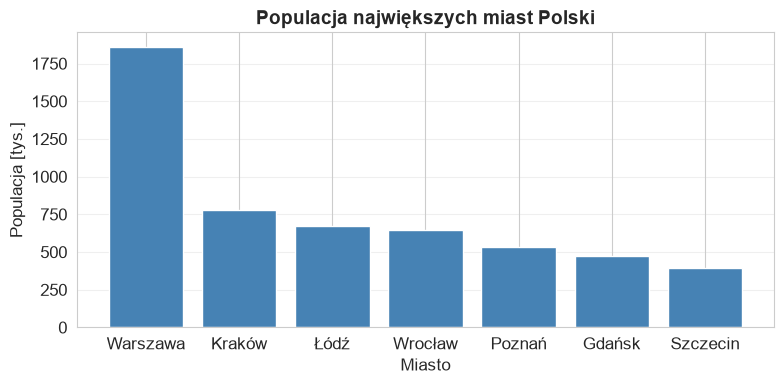

In [85]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(miasta_sort["Miasto"], miasta_sort["Populacja_tys"], color="steelblue")

ax.set_title("Populacja największych miast Polski", fontsize=14, fontweight="bold")
ax.set_xlabel("Miasto")
ax.set_ylabel("Populacja [tys.]")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Metoda 2: pandas

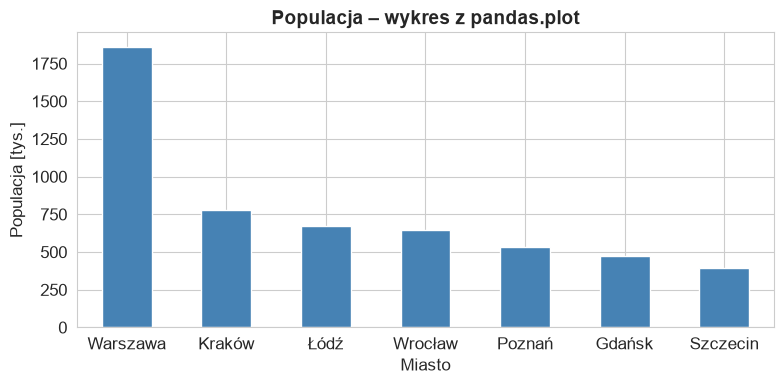

In [86]:
ax = miasta_sort.plot.bar(x="Miasto", y="Populacja_tys", color="steelblue",
                         legend=False, rot=0, figsize=(8, 4))

ax.set_title("Populacja – wykres z pandas.plot", fontsize=14, fontweight="bold")
ax.set_ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

### Metoda 3: seaborn

Seaborn pozwala jednym parametrem pokolorować słupki według innej kolumny (`hue`) – tu według kategorii z części A.

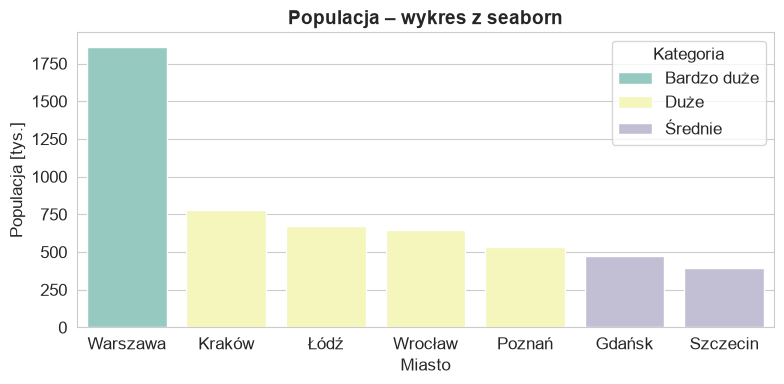

In [87]:
plt.figure(figsize=(8, 4))
sns.barplot(data=miasta_sort, x="Miasto", y="Populacja_tys", hue="Kategoria")

plt.title("Populacja – wykres z seaborn", fontsize=14, fontweight="bold")
plt.ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

> **Uwaga:** oś Y na wykresie słupkowym zawsze zaczynamy od zera. Ucięta oś (np. od 300 tys.) sprawiłaby, że różnice wyglądałyby na wielokrotnie większe, niż są.

## CZĘŚĆ 8: WYKRES PUNKTOWY – relacja dwóch zmiennych

**Pytanie:** czy miasta o większej powierzchni mają więcej mieszkańców?

### Metoda 1: matplotlib (z podpisami punktów)

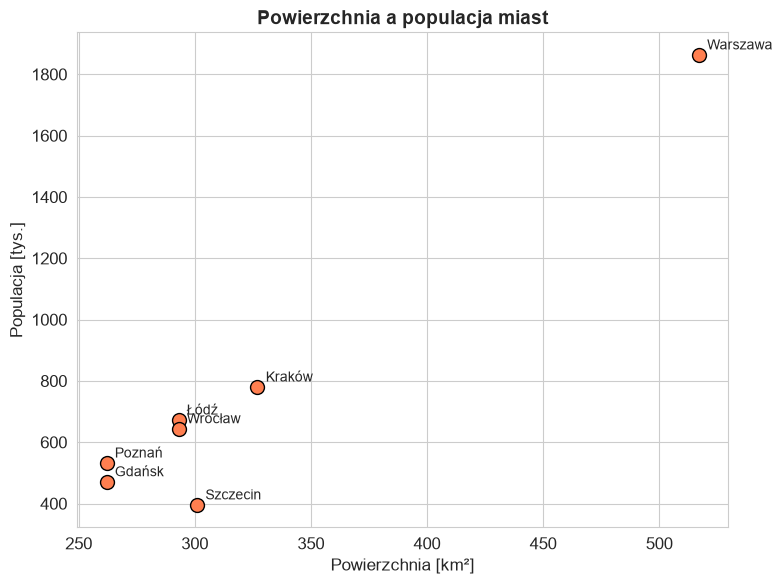

In [88]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(miasta["Powierzchnia_km2"], miasta["Populacja_tys"],
           s=100, color="coral", edgecolors="black")

# Podpisujemy każdy punkt nazwą miasta
for _, wiersz in miasta.iterrows():
    ax.annotate(wiersz["Miasto"],
                (wiersz["Powierzchnia_km2"], wiersz["Populacja_tys"]),
                textcoords="offset points", xytext=(6, 4), fontsize=10)

ax.set_title("Powierzchnia a populacja miast", fontsize=14, fontweight="bold")
ax.set_xlabel("Powierzchnia [km²]")
ax.set_ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

### Metoda 2: pandas

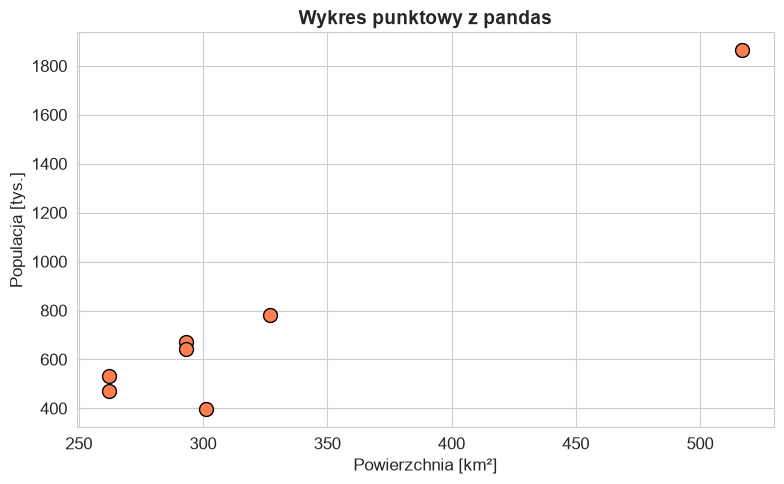

In [89]:
miasta.plot.scatter(x="Powierzchnia_km2", y="Populacja_tys",
                    s=100, color="coral", edgecolors="black", figsize=(8, 5))
plt.title("Wykres punktowy z pandas", fontsize=14, fontweight="bold")
plt.xlabel("Powierzchnia [km²]")
plt.ylabel("Populacja [tys.]")
plt.tight_layout()
plt.show()

### Metoda 3: seaborn

Kolor (`hue`) i wielkość punktu (`size`) mogą przenosić kolejne zmienne – tu kategorię i gęstość zaludnienia.

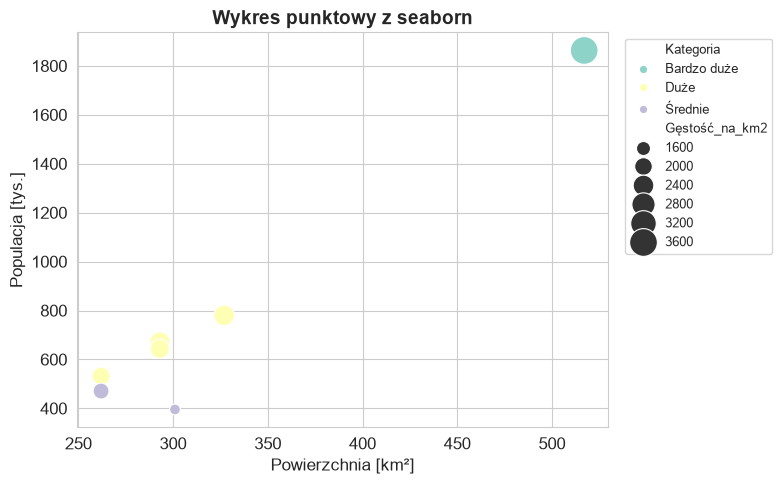

In [90]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=miasta, x="Powierzchnia_km2", y="Populacja_tys",
                hue="Kategoria", size="Gęstość_na_km2", sizes=(60, 400))

plt.title("Wykres punktowy z seaborn", fontsize=14, fontweight="bold")
plt.xlabel("Powierzchnia [km²]")
plt.ylabel("Populacja [tys.]")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

> **Myślenie eksploracyjne:** mamy tylko 7 punktów, a Warszawa odstaje w obu wymiarach. Czy bez niej zależność nadal byłaby widoczna? Z tak małej próby nie wyciągamy mocnych wniosków.

## CZĘŚĆ 9: WYKRES LINIOWY i FORMAT SZEROKI vs DŁUGI

**Pytanie:** jak zmienia się temperatura w ciągu roku w różnych miastach?

DataFrame `temperatura` jest w **formacie szerokim**: jeden wiersz = jedno miasto, a miesiące są *nazwami kolumn*.

In [91]:
miesiace = ["Styczeń", "Kwiecień", "Lipiec", "Październik"]

# Indeksem są miasta, kolumnami – miesiące
temp_szeroka = temperatura.set_index("Miasto")[miesiace]
temp_szeroka

,Styczeń,Kwiecień,Lipiec,Październik
Miasto,,,,
Warszawa,-2,9,19,9
Kraków,-1,10,20,9
Gdańsk,0,8,17,10
Wrocław,-1,11,21,10
Poznań,-2,10,19,9
Łódź,-3,9,20,8


### Metoda 1: matplotlib – pętla po wierszach

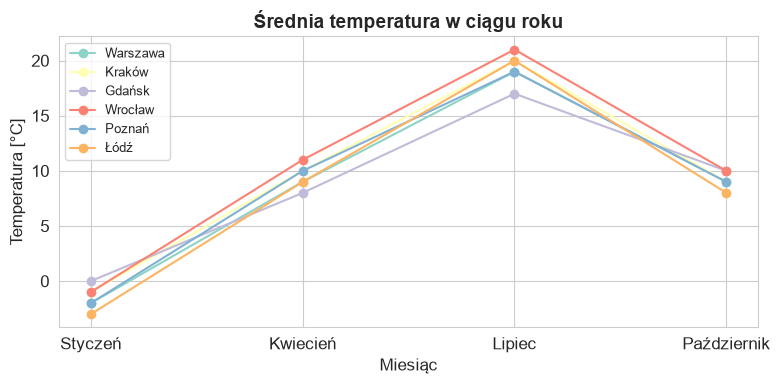

In [92]:
fig, ax = plt.subplots(figsize=(8, 4))
for miasto, wiersz in temp_szeroka.iterrows():
    ax.plot(miesiace, wiersz.values, marker="o", label=miasto)

ax.set_title("Średnia temperatura w ciągu roku", fontsize=14, fontweight="bold")
ax.set_xlabel("Miesiąc")
ax.set_ylabel("Temperatura [°C]")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Metoda 2: pandas – lubi format szeroki

`.plot()` rysuje **każdą kolumnę jako osobną linię**, a indeks trafia na oś X. Chcemy miesiące na osi X, więc transponujemy tabelę (`.T`).

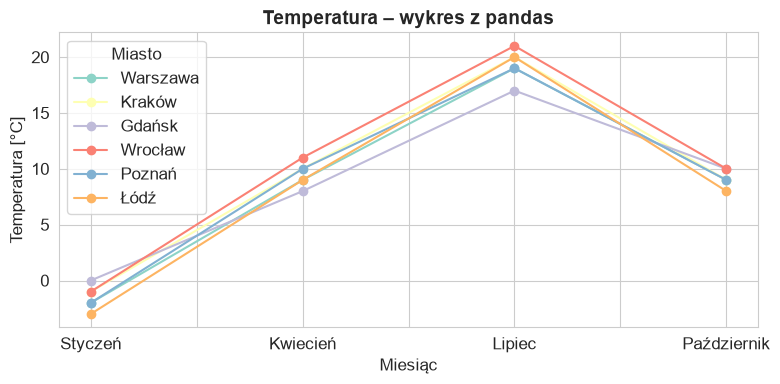

In [93]:
temp_szeroka.T.plot(marker="o", figsize=(8, 4))

plt.title("Temperatura – wykres z pandas", fontsize=14, fontweight="bold")
plt.xlabel("Miesiąc")
plt.ylabel("Temperatura [°C]")
plt.tight_layout()
plt.show()

### Format długi: `pd.melt()`

Seaborn potrzebuje **formatu długiego**: jeden wiersz = jedna obserwacja (miasto, miesiąc, temperatura), a każda zmienna jest osobną kolumną. Dopiero wtedy „miesiąc” jest kolumną, którą możemy podpiąć pod oś X, a „miasto” – pod kolor (`hue`).

In [94]:
temp_dluga = temperatura.melt(id_vars="Miasto",
                              value_vars=miesiace,
                              var_name="Miesiąc",
                              value_name="Temperatura")

print("Format szeroki:", temp_szeroka.shape)
print("Format długi:  ", temp_dluga.shape)
temp_dluga.head(8)

Format szeroki: (6, 4)
Format długi:   (24, 3)


,Miasto,Miesiąc,Temperatura
0,Warszawa,Styczeń,-2
1,Kraków,Styczeń,-1
2,Gdańsk,Styczeń,0
3,Wrocław,Styczeń,-1
4,Poznań,Styczeń,-2
5,Łódź,Styczeń,-3
6,Warszawa,Kwiecień,9
7,Kraków,Kwiecień,10


### Metoda 3: seaborn

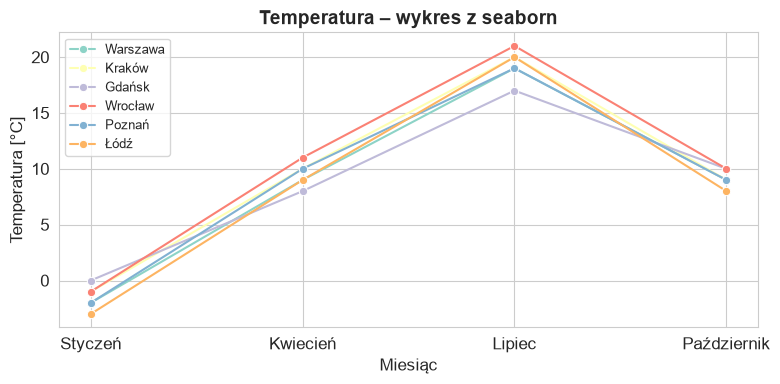

In [95]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=temp_dluga, x="Miesiąc", y="Temperatura",
             hue="Miasto", marker="o")

plt.title("Temperatura – wykres z seaborn", fontsize=14, fontweight="bold")
plt.ylabel("Temperatura [°C]")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

Z tych samych danych w formacie długim jedną linijką zmienimy typ wykresu – np. na słupki pogrupowane według miesiąca:

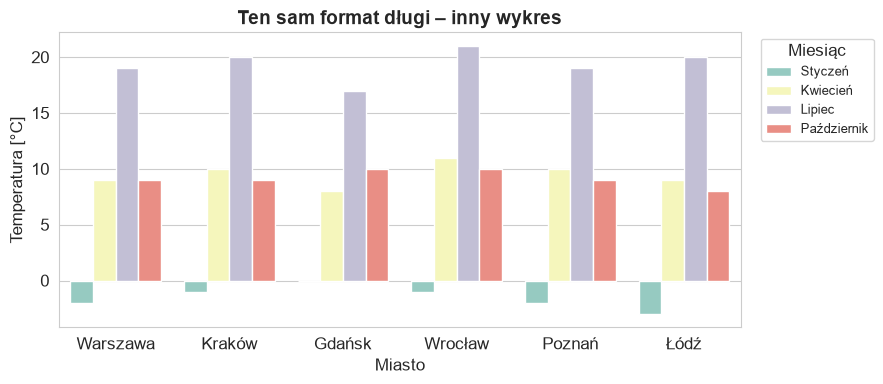

In [96]:
plt.figure(figsize=(9, 4))
sns.barplot(data=temp_dluga, x="Miasto", y="Temperatura", hue="Miesiąc")
plt.title("Ten sam format długi – inny wykres", fontsize=14, fontweight="bold")
plt.ylabel("Temperatura [°C]")
plt.legend(title="Miesiąc", fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Z powrotem: `pivot()`

Operacją odwrotną do `melt()` jest `pivot()`. Uwaga: kolumny zostaną posortowane alfabetycznie – kolejność miesięcy przywracamy, wybierając je listą.

In [97]:
temp_dluga.pivot(index="Miasto", columns="Miesiąc", values="Temperatura")[miesiace]

Miesiąc,Styczeń,Kwiecień,Lipiec,Październik
Miasto,,,,
Gdańsk,0,8,17,10
Kraków,-1,10,20,9
Poznań,-2,10,19,9
Warszawa,-2,9,19,9
Wrocław,-1,11,21,10
Łódź,-3,9,20,8


# **Zadania – część B**

Każdy wykres musi mieć tytuł, opisy osi (z jednostkami) i – jeśli jest więcej niż jedna seria – legendę.

## **Zadanie 7: Wykres liniowy i brakujące dane**

Liczba mieszkańców Warszawy i Łodzi w wybranych latach:

| Rok  | Warszawa  | Łódź      |
|------|-----------|-----------|
| 2002 | 1672000   | 789318    |
| 2011 | 1707000   | 728892    |
| 2015 | 1740000   | brak      |
| 2022 | 1795000   | 670642    |

a) Utwórz słownik z powyższymi danymi (użyj `None` dla brakującej wartości) i stwórz z niego DataFrame.

b) Zapisz DataFrame do pliku `populacja_miast.csv`, a następnie wczytaj go z powrotem.

c) Narysuj wykres liniowy zmian populacji obu miast w matplotlib – różne kolory i markery dla miast.

d) Narysuj ten sam wykres w seaborn (wskazówka: najpierw `melt`).

e) Co dzieje się z linią Łodzi w roku 2015? Czym różni się wynik, jeśli przed rysowaniem usuniesz wiersz z brakiem (`dropna()`)? Który wykres lepiej oddaje dane?

In [98]:
population_data = {
    "Rok": [2002, 2011, 2015, 2022],
    "Warszawa": [1672000, 1707000, 1740000, 1795000],
    "Łódż": [789318, 728892, None, 670642]
}

df_population = pd.DataFrame(population_data)
df_population.to_csv("populacja_miast.csv", index=False)

df_population = pd.read_csv("populacja_miast.csv")


<Axes: xlabel='Rok'>

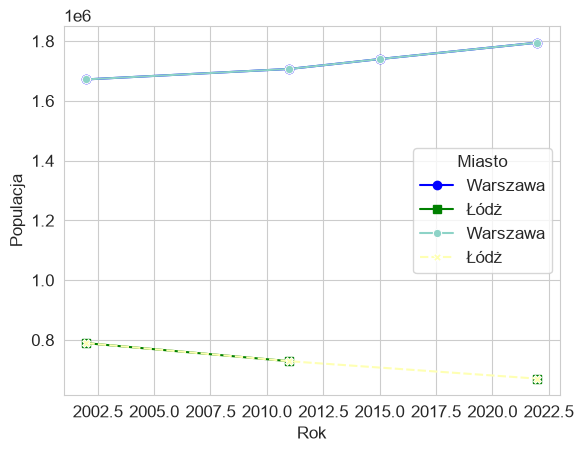

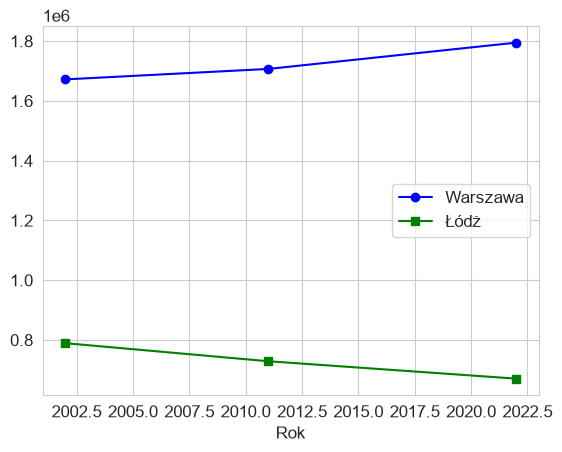

In [99]:
df_population.plot(x="Rok", y=["Warszawa", "Łódż"], style=["-o", "-s"], kind="line", color=["blue", "green"])

df_melt = df_population.melt(id_vars="Rok", value_vars=["Warszawa", "Łódż"], var_name="Miasto", value_name="Populacja")
sns.lineplot(data=df_melt, x="Rok", y="Populacja", hue="Miasto", style="Miasto", markers=True)

df_population.dropna().plot(x="Rok", y=["Warszawa", "Łódż"], style=["-o", "-s"], kind="line", color=["blue", "green"])
# Wykres po dropna() całkowicie usuwa rok 2015, przez co tracimy poprawny punkt dla Warszawy, a dla Łodzi sztucznie łączy lata
# 2011 i 2022 jedną prostą linią. Wykres z brakami lepiej oddaje realne dane, bo nie ukrywa luki w pomiarach i nie fałszuje
# przebiegu trendu.


## **Zadanie 8: Wykres punktowy z linią trendu**

a) Wygeneruj 100 losowych obserwacji:
   - `godziny_nauki` – liczby z przedziału od 0 do 10,
   - `ocena` – obliczona jako `50 + godziny_nauki * 5 + szum`, gdzie szum to losowe liczby od −10 do 10.

b) Stwórz z nich DataFrame.

c) Narysuj wykres punktowy zależności oceny od liczby godzin nauki.

d) Dodaj linię trendu (`sns.regplot`). Czy zależność jest wyraźna?

In [100]:
np.random.seed(42)
study_hours = np.random.uniform(0, 10, 100)
noise = np.random.uniform(-10, 10, 100)
grades = 50 + study_hours * 5 + noise


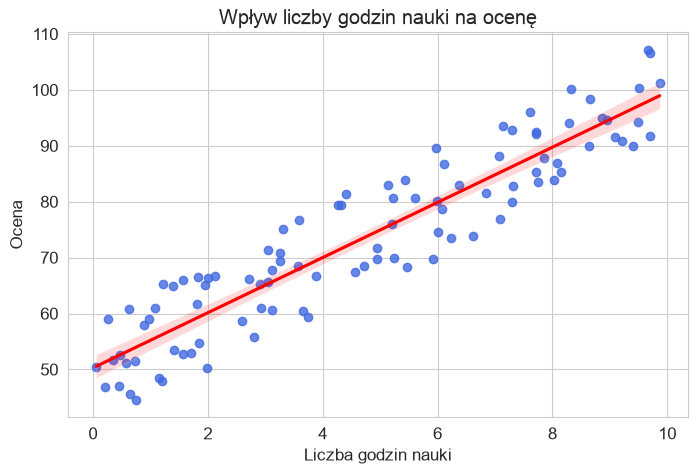

In [101]:
study_data = pd.DataFrame({
    "godziny_nauki": study_hours,
    "ocena": grades
})
plt.figure(figsize=(8, 5))
sns.regplot(data=study_data, x="godziny_nauki", y="ocena", color="royalblue", line_kws={"color": "red"})

plt.title("Wpływ liczby godzin nauki na ocenę")
plt.xlabel("Liczba godzin nauki")
plt.ylabel("Ocena")
plt.show()

# Tak, zależność jest wyraźna i dodatnia. Punkty układają się wzdłuż rosnącej linii prostej. Mimo losowego szumu,
# widać wyraźny trend: każda dodatkowa godzina nauki podnosi wynik średnio o około 5 punktów.


## **Zadanie 9: Poziomy wykres słupkowy**

Przeciętne miesięczne wynagrodzenie w wybranych miastach (dane przykładowe):

| Miasto    | Wynagrodzenie [PLN] |
|-----------|---------------------|
| Warszawa  | 8500                |
| Kraków    | 7200                |
| Wrocław   | 7400                |
| Poznań    | 7100                |
| Gdańsk    | 6900                |
| Łódź      | 6300                |

a) Utwórz DataFrame z powyższymi danymi.

b) Narysuj **poziomy** wykres słupkowy (`barh` w matplotlib lub `sns.barplot(..., orient="h")`).

c) Posortuj miasta tak, żeby najwyższe wynagrodzenie było na górze.

d) Dodaj wartości na końcach słupków (wskazówka: `ax.bar_label(...)`).

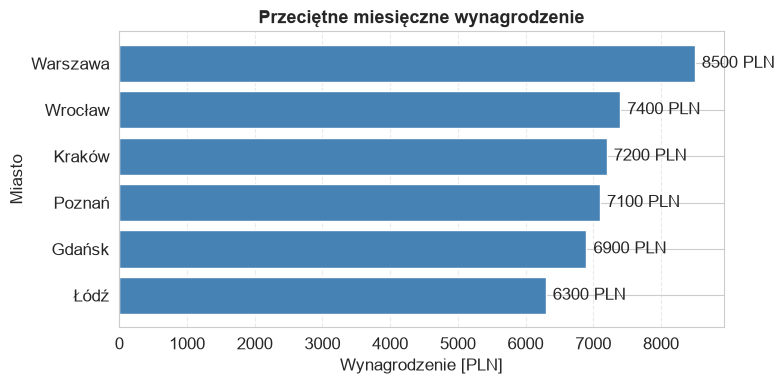

In [102]:
# a
salary_data = {
    "Miasto": ["Warszawa", "Kraków", "Wrocław", "Poznań", "Gdańsk", "Łódź"],
    "Wynagrodzenie": [8500, 7200, 7400, 7100, 6900, 6300]
}
df_salaries = pd.DataFrame(salary_data)

# c
df_sorted = df_salaries.sort_values(by="Wynagrodzenie", ascending=True)

# b & d
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(df_sorted["Miasto"], df_sorted["Wynagrodzenie"], color="steelblue")
ax.bar_label(bars, padding=5, fmt="%d PLN")

ax.set_title("Przeciętne miesięczne wynagrodzenie", fontsize=13, fontweight="bold")
ax.set_xlabel("Wynagrodzenie [PLN]")
ax.set_ylabel("Miasto")
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## **Zadanie 10 (dodatkowe): Format długi w praktyce**

Wykorzystaj DataFrame `wyniki_egzaminy` z zadania zaawansowanego.

a) Przekształć go do formatu długiego: kolumny `Student`, `Kierunek`, `Przedmiot`, `Wynik` (wskazówka: `melt` z `id_vars=["Student", "Kierunek"]` i `value_vars` = trzy przedmioty).

b) Narysuj `sns.barplot` z przedmiotem na osi X, wynikiem na osi Y i kierunkiem jako `hue`.

c) Czy studenci danego kierunku osiągają najlepsze wyniki z „własnego” przedmiotu?

d) Dlaczego ten wykres trudno byłoby narysować z danych w formacie szerokim?

     Student     Kierunek    Przedmiot  Wynik
0       Anna  Informatyka   Matematyka     85
1     Bartek       Fizyka   Matematyka     92
2     Celina   Matematyka   Matematyka     78
3     Damian  Informatyka   Matematyka     88
4        Ewa   Matematyka   Matematyka     95
5      Filip  Informatyka   Matematyka     72
6   Gabriela       Fizyka   Matematyka     89
7     Hubert   Matematyka   Matematyka     81
8       Anna  Informatyka       Fizyka     78
9     Bartek       Fizyka       Fizyka     88
10    Celina   Matematyka       Fizyka     82
11    Damian  Informatyka       Fizyka     75
12       Ewa   Matematyka       Fizyka     91
13     Filip  Informatyka       Fizyka     68
14  Gabriela       Fizyka       Fizyka     85
15    Hubert   Matematyka       Fizyka     79
16      Anna  Informatyka  Informatyka     92
17    Bartek       Fizyka  Informatyka     85
18    Celina   Matematyka  Informatyka     88
19    Damian  Informatyka  Informatyka     90
20       Ewa   Matematyka  Informa

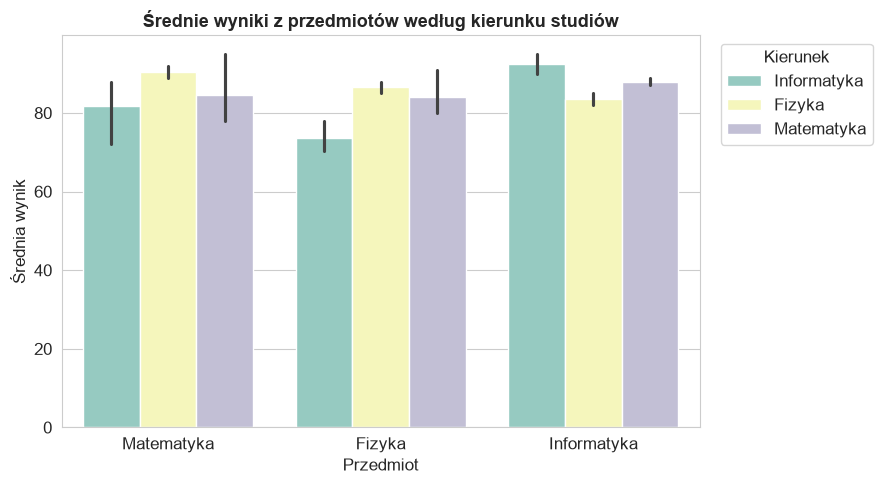

In [103]:
exam_results_long = wyniki_egzaminy.melt(
    id_vars=["Student", "Kierunek"],
    value_vars=["Matematyka", "Fizyka", "Informatyka"],
    var_name="Przedmiot",
    value_name="Wynik"
)

print(exam_results_long)

plt.figure(figsize=(9, 5))
sns.barplot(data=exam_results_long, x="Przedmiot", y="Wynik", hue="Kierunek")

plt.title("Średnie wyniki z przedmiotów według kierunku studiów", fontsize=13, fontweight="bold")
plt.xlabel("Przedmiot")
plt.ylabel("Średnia wynik")
plt.legend(title="Kierunek", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# c
# Nie w każdym przypadku. Informatyka: studenci Informatyki mają najwyższą średnią (~92.3 pkt).
# Fizyka: studenci Fizyki mają najwyższą średnią (~86.5 pkt).
# Matematyka: studenci Fizyki uzyskali wyższą średnią (90.5 pkt) niż studenci Matematyki (84.7 pkt).
# d
# W formacie szerokim przedmioty to nazwy kolumn, a kierunki to wartości w wierszach.
# Biblioteki wizualizacji (Seaborn/Matplotlib) nie potrafią grupować jednocześnie po nagłówkach kolumn i
# wartościach w komórkach bez żmudnego, ręcznego filtrowania tabeli i ręcznego przeliczania pozycji słupków.
# Format długi zamienia nagłówki w zwykłe dane kategoryczne (Przedmiot), co pozwala na automatyczne
# grupowanie przez parametry x i hue.
